In [1]:
import pandas as pd

df = pd.read_csv("../heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [2]:
print("Shape of dataset:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget value distribution:")
print(df['target'].value_counts())


Shape of dataset: (1025, 14)

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target value distribution:
target
1    526
0    499
Name: count, dtype: int64


C:\Users\Gauresh\AppData\Local\Temp\ipykernel_10572\3225508317.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2')


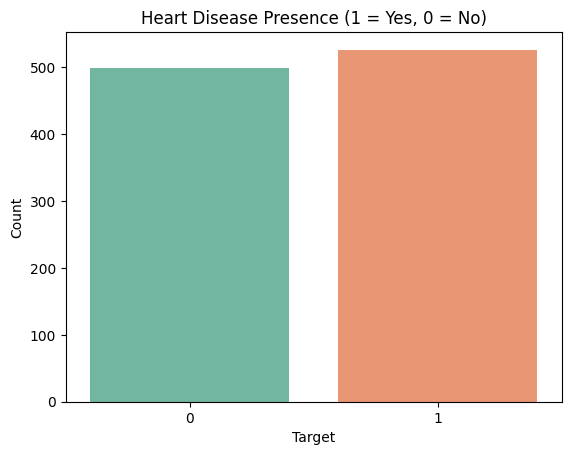

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='target', data=df, palette='Set2')
plt.title("Heart Disease Presence (1 = Yes, 0 = No)")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()


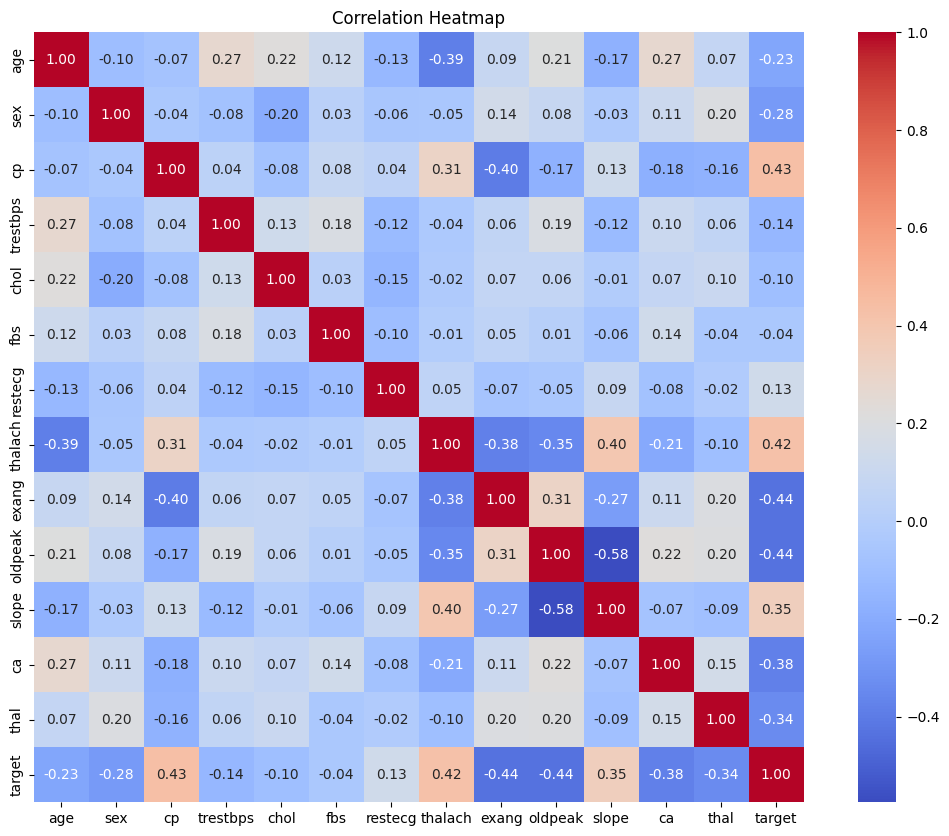

In [8]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap")
plt.show()

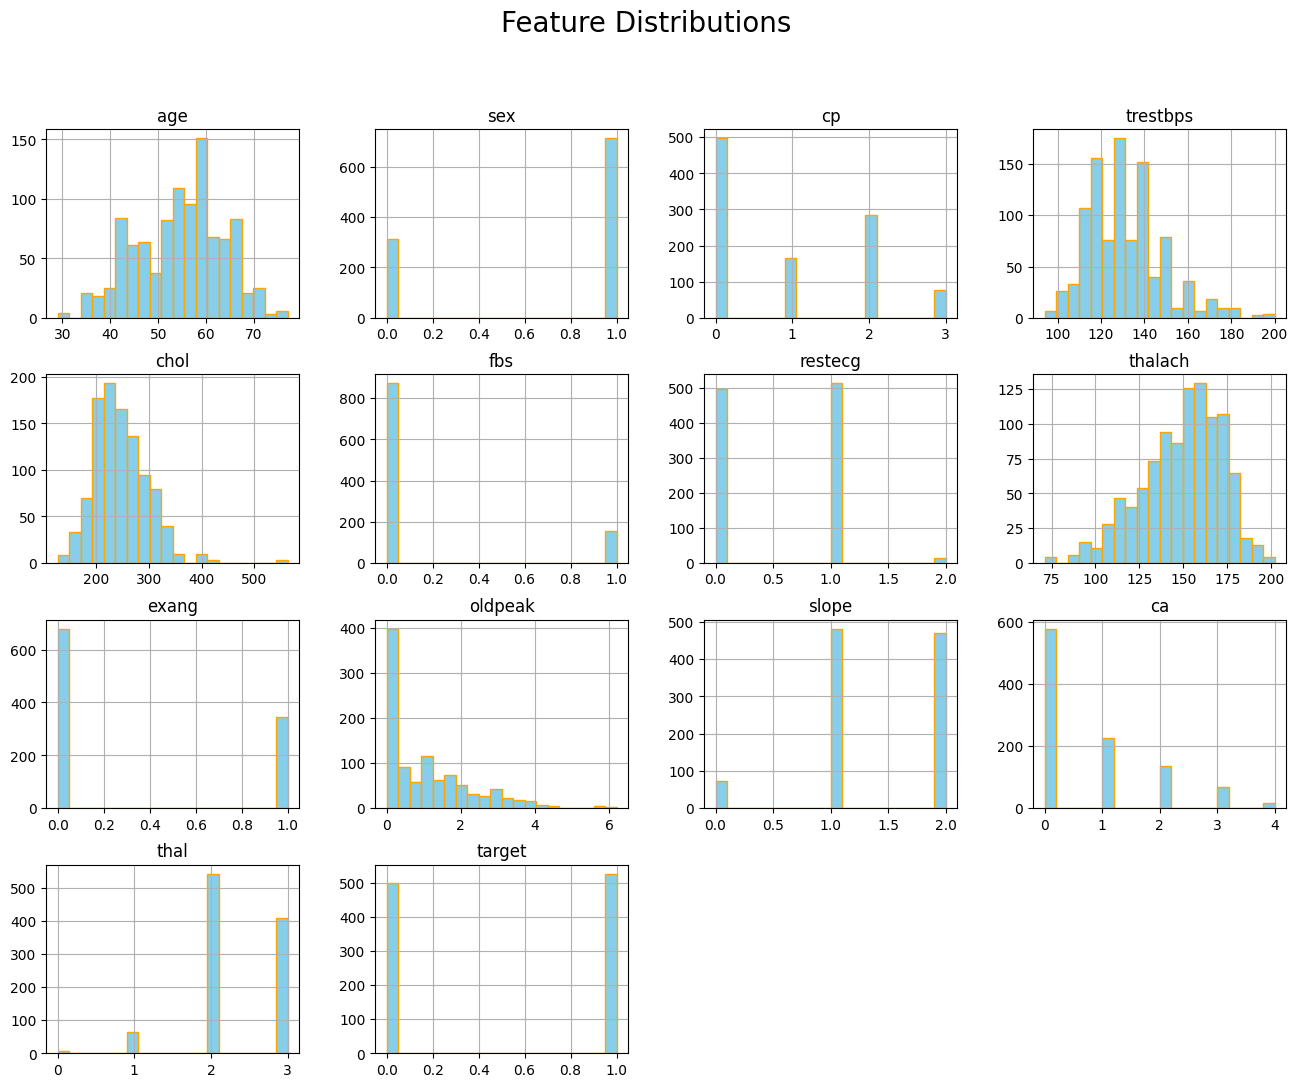

In [10]:
df.hist(figsize=(16, 12), bins=20, color='skyblue', edgecolor='orange')
plt.suptitle("Feature Distributions", fontsize=20)
plt.show()

C:\Users\Gauresh\AppData\Local\Temp\ipykernel_10572\802962518.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='Set3')


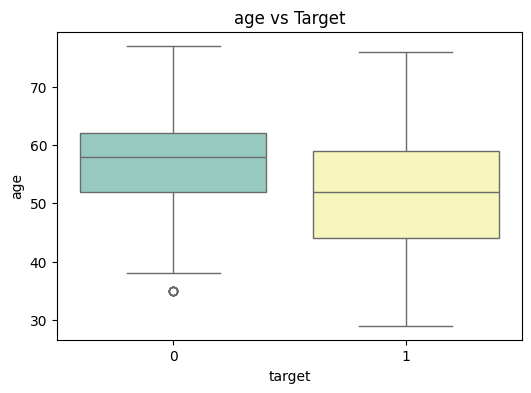

C:\Users\Gauresh\AppData\Local\Temp\ipykernel_10572\802962518.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='Set3')


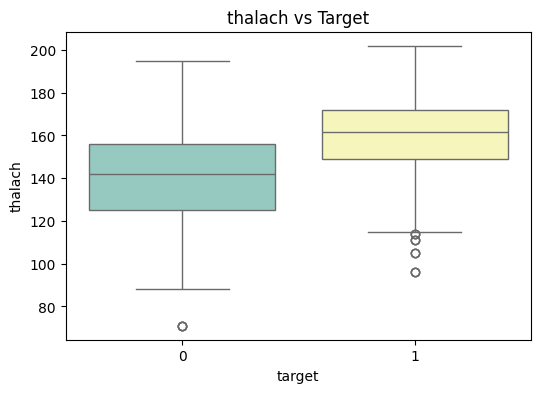

C:\Users\Gauresh\AppData\Local\Temp\ipykernel_10572\802962518.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='Set3')


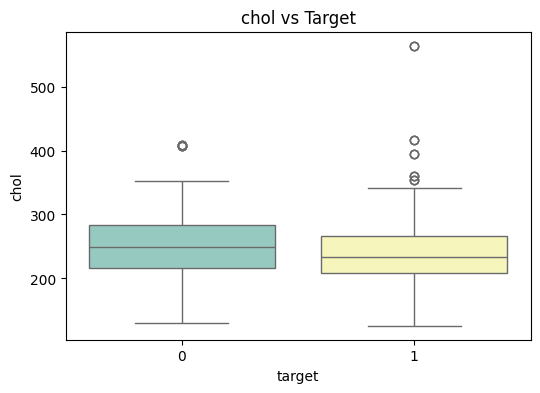

C:\Users\Gauresh\AppData\Local\Temp\ipykernel_10572\802962518.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='Set3')


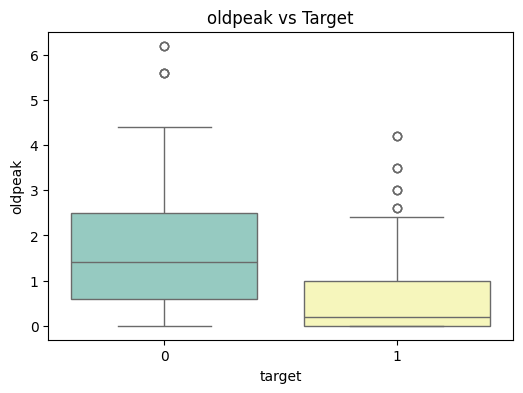

C:\Users\Gauresh\AppData\Local\Temp\ipykernel_10572\802962518.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='Set3')


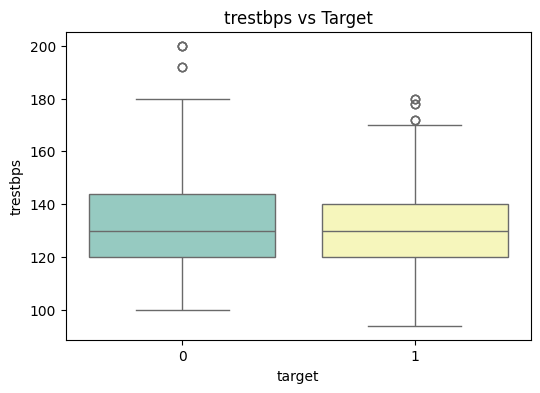

In [11]:
features = ['age', 'thalach', 'chol', 'oldpeak', 'trestbps']

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='target', y=feature, data=df, palette='Set3')
    plt.title(f"{feature} vs Target")
    plt.show()

In [12]:
df_encoded = pd.get_dummies(df, columns=['cp', 'thal', 'slope'], drop_first=True)

print("New shape after encoding:", df_encoded.shape)

New shape after encoding: (1025, 19)


In [14]:
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (820, 18)
Test shape: (205, 18)


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       102
           1       1.00      1.00      1.00       103

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205


Confusion Matrix:
 [[102   0]
 [  0 103]]


In [18]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))


Logistic Regression Accuracy: 0.8195121951219512


In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))


KNN Accuracy: 0.8390243902439024


In [20]:
import joblib

joblib.dump(rf, '../heart_disease_model.pkl')
print("Model saved as '../heart_disease_model.pkl'")


Model saved as 'heart_disease_model.pkl'


In [22]:
joblib.dump(scaler, '../scaler.pkl')
print("Scaler saved as '../scaler.pkl'")


Scaler saved as 'scaler.pkl'


In [1]:
import gradio as gr
import numpy as np
import joblib

model = joblib.load('../heart_disease_model.pkl')
scaler = joblib.load('../scaler.pkl')

def predict_heart_disease(age, sex, trestbps, chol, fbs, restecg, thalach,
                          exang, oldpeak, ca, cp_1, cp_2, cp_3, thal_1, thal_2,
                          thal_3, slope_1, slope_2):
    
    input_data = np.array([[age, sex, trestbps, chol, fbs, restecg, thalach,
                            exang, oldpeak, ca, cp_1, cp_2, cp_3, thal_1, thal_2,
                            thal_3, slope_1, slope_2]])
    
    input_scaled = scaler.transform(input_data)
    prediction = model.predict(input_scaled)[0]
    
    return "Heart Disease Detected!" if prediction == 1 else "No Heart Disease Detected"

inputs = [
    gr.Number(label="Age"),
    gr.Radio(choices=[0, 1], label="Sex (0 = Female, 1 = Male)"),
    gr.Number(label="Resting Blood Pressure (trestbps)"),
    gr.Number(label="Cholesterol (chol)"),
    gr.Radio(choices=[0, 1], label="Fasting Blood Sugar > 120 mg/dl"),
    gr.Radio(choices=[0, 1, 2], label="Resting ECG (restecg)"),
    gr.Number(label="Maximum Heart Rate (thalach)"),
    gr.Radio(choices=[0, 1], label="Exercise-induced Angina"),
    gr.Number(label="Oldpeak (ST depression)"),
    gr.Radio(choices=[0, 1, 2, 3], label="Number of Major Vessels (ca)"),
   
    gr.Checkbox(label="Chest Pain Type: cp_1"),
    gr.Checkbox(label="Chest Pain Type: cp_2"),
    gr.Checkbox(label="Chest Pain Type: cp_3"),
    
    gr.Checkbox(label="Thal: 1 (Normal)"),
    gr.Checkbox(label="Thal: 2 (Fixed defect)"),
    gr.Checkbox(label="Thal: 3 (Reversible defect)"),
    
    gr.Checkbox(label="Slope: 1"),
    gr.Checkbox(label="Slope: 2"),
]

gr.Interface(fn=predict_heart_disease, inputs=inputs, outputs="text",
             title="Heart Disease Predictor",
             description="Enter patient details to predict risk of heart disease."
).launch()


* Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.
